In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
train_dir = "../datasets/train"
val_dir = "../datasets/valid"
test_dir = "../datasets/test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [3]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 4389 files belonging to 22 classes.
Found 110 files belonging to 22 classes.
Found 110 files belonging to 22 classes.


In [4]:
class_names = train_dataset.class_names

print("Number of classes:", len(class_names))
print(class_names)

Number of classes: 21
['Alstonia Scholaris diseased (P2a)', 'Alstonia Scholaris healthy (P2b)', 'Arjun diseased (P1a)', 'Arjun healthy (P1b)', 'Bael diseased (P4b)', 'Basil healthy (P8)', 'Chinar diseased (P11b)', 'Chinar healthy (P11a)', 'Gauva diseased (P3b)', 'Gauva healthy (P3a)', 'Jamun diseased (P5b)', 'Jamun healthy (P5a)', 'Jatropha diseased (P6b)', 'Jatropha healthy (P6a)', 'Lemon diseased (P10b)', 'Lemon healthy (P10a)', 'Mango diseased (P0b)', 'Mango healthy (P0a)', 'Pomegranate diseased (P9b)', 'Pomegranate healthy (P9a)', 'Pongamia Pinnata diseased (P7b)']


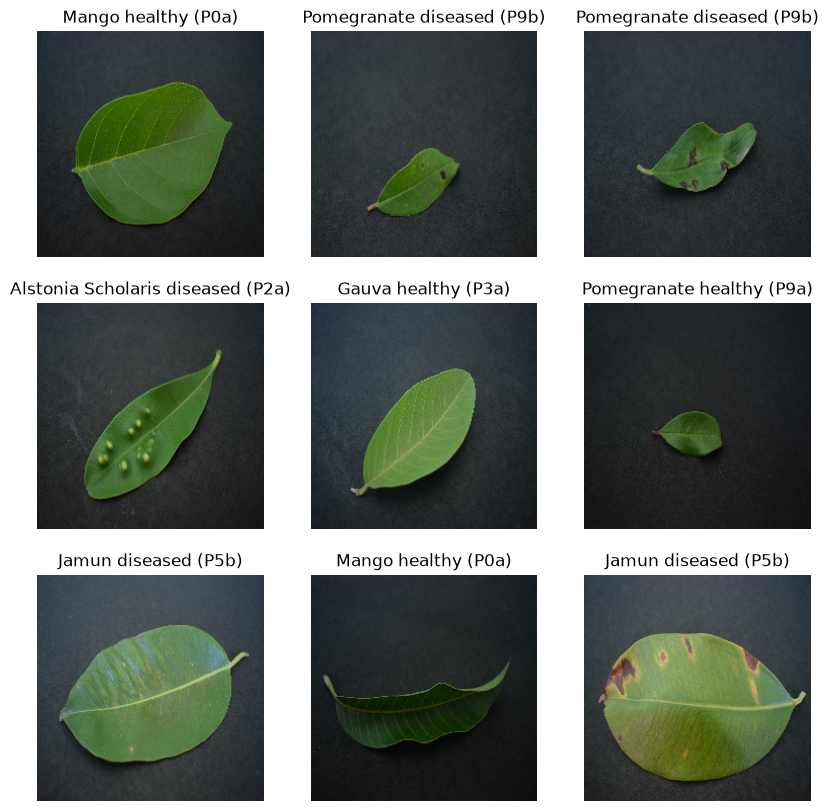

In [5]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

OPTIMIZE THE DATASET PIPELINE

In [10]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

DATA AUGMENTATION

In [4]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2)
])

BUILDING EfficientNetB0 Model

In [6]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

Creating Model

In [7]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.efficientnet.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

Number of classes: 22


MODEL SUMMARY

In [10]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 21)             │        26,901 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,076,472 (15.55 MB)

 Trainable params: 26,901 (105.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

COMPILING THE MODEL

In [31]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

CREATING CALLBACKS

In [17]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "../models/TreeHealth_EfficientNetB0.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

In [15]:
import os

print("Train folders:", len(os.listdir(train_dir)))
print("Validation folders:", len(os.listdir(val_dir)))
print("Test folders:", len(os.listdir(test_dir)))

Train folders: 22
Validation folders: 22
Test folders: 22


In [33]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

Epoch 1/20


d:\AI Tree Predictor\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 932ms/step - accuracy: 0.4810 - loss: 1.8358
Epoch 1: val_accuracy improved from None to 0.46364, saving model to ../models/TreeHealth_EfficientNetB0.keras

Epoch 1: finished saving model to ../models/TreeHealth_EfficientNetB0.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 164s 974ms/step - accuracy: 0.4810 - loss: 1.8358 - val_accuracy: 0.4636 - val_loss: 1.8031 - learning_rate: 0.0010
Epoch 2/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7154 - loss: 1.0623
Epoch 2: val_accuracy improved from 0.46364 to 0.47273, saving model to ../models/TreeHealth_EfficientNetB0.keras

Epoch 2: finished saving model to ../models/TreeHealth_EfficientNetB0.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 331s 2s/step - accuracy: 0.7154 - loss: 1.0623 - val_accuracy: 0.4727 - val_loss: 1.5147 - learning_rate: 0.0010
Epoch 3/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7644 - loss: 0.8465
Epoch 3: val_accuracy improved from 0.47273 to 0.52727, saving model to ../models/TreeH

In [21]:
import os

print("Train:", len(os.listdir(train_dir)))
print("Validation:", len(os.listdir(val_dir)))
print("Test:", len(os.listdir(test_dir)))

Train: 22
Validation: 22
Test: 22


In [32]:
print(model.output_shape)

(None, 22)


In [34]:
import os

print(os.path.exists("../models/TreeHealth_EfficientNetB0.keras"))

True


LOAD TRAINED MODEL

In [11]:
import tensorflow as tf

model = tf.keras.models.load_model("../models/TreeHealth_EfficientNetB0.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [5]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 110 files belonging to 22 classes.


Evaluate Model

In [6]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 514ms/step - accuracy: 0.6545 - loss: 1.0254

Test Accuracy: 0.6545
Test Loss: 1.0254


SAVE THE TRAINING HISTORY

In [7]:
print('history' in globals())

False


Save Class names

In [8]:
import json

class_names = test_dataset.class_names

with open("../models/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved successfully!")

Class names saved successfully!


saving best model

In [9]:
model.save("../models/Final_TreeHealth_EfficientNetB0.keras")

print("Final model saved successfully!")

Final model saved successfully!


check

In [10]:
import os

print(os.listdir("../models"))

['class_names.json', 'Final_TreeHealth_EfficientNetB0.keras', 'TreeHealth_EfficientNetB0.keras']


UNFREEZE THE MODEL

In [12]:
base_model = model.get_layer("efficientnetb0")

print(base_model)

<Functional name=efficientnetb0, built=True>


In [13]:
base_model.trainable = True

print("Trainable:", base_model.trainable)

Trainable: True


FREEZING all layers except last 30

In [14]:
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Fine-tuning setup completed!")

Fine-tuning setup completed!


In [15]:
trainable_count = sum(layer.trainable for layer in base_model.layers)

print("Trainable layers:", trainable_count)
print("Total layers:", len(base_model.layers))

Trainable layers: 30
Total layers: 238


RECOMPILE

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
fine_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8396 - loss: 0.5822
Epoch 1: val_accuracy did not improve from 0.57273
138/138 ━━━━━━━━━━━━━━━━━━━━ 261s 2s/step - accuracy: 0.8396 - loss: 0.5822 - val_accuracy: 0.5636 - val_loss: 1.1046 - learning_rate: 5.0000e-06
Epoch 2/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8412 - loss: 0.5706
Epoch 2: val_accuracy did not improve from 0.57273
138/138 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.8412 - loss: 0.5706 - val_accuracy: 0.5727 - val_loss: 1.0968 - learning_rate: 5.0000e-06
Epoch 3/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8471 - loss: 0.5438
Epoch 3: val_accuracy improved from 0.57273 to 0.58182, saving model to ../models/TreeHealth_EfficientNetB0.keras

Epoch 3: finished saving model to ../models/TreeHealth_EfficientNetB0.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 448s 3s/step - accuracy: 0.8471 - loss: 0.5438 - val_accuracy: 0.5818 - val_loss: 1.0854 - learning_rate: 5.0000e-06
Epoch 4/15
138

EVALUATE MODEL

In [20]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 626ms/step - accuracy: 0.6909 - loss: 0.9263

Test Accuracy: 0.6909
Test Loss: 0.9263


GENERATE PREDICTIONS

In [21]:
import numpy as np

predictions = model.predict(test_dataset)

y_pred = np.argmax(predictions, axis=1)

4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step  


GET TRUE LABELS

In [22]:
y_true = np.concatenate(
    [labels.numpy() for images, labels in test_dataset],
    axis=0
)

CLASSIFICATION REPORT

In [23]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                                   precision    recall  f1-score   support

Alstonia Scholaris diseased (P2a)       0.38      1.00      0.56         5
 Alstonia Scholaris healthy (P2b)       0.80      0.80      0.80         5
             Arjun diseased (P1a)       1.00      0.80      0.89         5
              Arjun healthy (P1b)       0.80      0.80      0.80         5
              Bael diseased (P4b)       0.83      1.00      0.91         5
               Basil healthy (P8)       1.00      1.00      1.00         5
           Chinar diseased (P11b)       1.00      0.40      0.57         5
            Chinar healthy (P11a)       0.60      0.60      0.60         5
             Gauva diseased (P3b)       1.00      0.60      0.75         5
              Gauva healthy (P3a)       1.00      1.00      1.00         5
             Jamun diseased (P5b)       0.67      0.80      0.73         5
              Jamun healthy (P5a)       0.83      1.00      0.91         5
          Jatropha disea

d:\AI Tree Predictor\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\AI Tree Predictor\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\AI Tree Predictor\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


SAVE THE FINAL MODEL

In [24]:
model.save("../models/Final_TreeHealth_EfficientNetB0.keras")

print("Final model saved successfully!")

Final model saved successfully!


SAVE THE CLASS NAMES

In [25]:
import json

with open("../models/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved successfully!")

Class names saved successfully!


In [1]:
import tensorflow as tf

print(tf.__version__)

2.21.0
